In [2]:
import pandas as pd
import numpy as np

import torch
from botorch.models import SingleTaskGP
from botorch.acquisition import qUpperConfidenceBound
from botorch.optim import optimize_acqf_discrete_local_search

from sklearn.preprocessing import MinMaxScaler
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 300

In [3]:
def data_convert(df:pd.DataFrame):
    target_cols =['Nluc template', 'Mg(OAc)2', 'NTPs', 'cap2','HEPES-KOH','pyrophosphatase', 'capped mRNA µg/µL']
    df = df[df['Capping efficiency'] != -1]
    df = df[target_cols]
    col_convert = {'Nluc template':'x0','Mg(OAc)2':'x1','NTPs':'x2','cap2':'x3','HEPES-KOH':'x4','pyrophosphatase':'x5','capped mRNA µg/µL':'y'}
    df = df.rename(columns=col_convert)
    return df

def run_bayes(data:pd.DataFrame,steps:list,maxs:list,mins:list,beta:float=2.0):
    # 実験における変数の数を定義
    num_x = len(data.columns)-1
    # 各変数の刻み幅(step),最小値(min),最大値(max),標準化後の刻み幅(norm_step),標準化後の定義域(norm_range)を定義
    norm_x_steps = []
    norm_x_ranges = []
    for i in range(num_x):
        tmp_step = steps[i]/(maxs[i]-mins[i])
        tmp_range = torch.Tensor(np.arange(0,1+tmp_step,tmp_step))
        norm_x_steps.append(tmp_step)
        norm_x_ranges.append(tmp_range)

    mmscaler = MinMaxScaler()
    norm_x = mmscaler.fit_transform(data.iloc[:,:-1])
    norm_x_df = pd.DataFrame(norm_x)
    y = data.iloc[:,-1].values
    norm_x_df.insert(len(data.columns)-1,'y',-y)
    norm_x_df.columns = data.columns
    norm_x_df
    #norm_x_df.to_csv('./data/round1_normed.csv')
    #norm_data = pd.read_csv("./data/round1_normed.csv", encoding="shift_jis",index_col=0)
    num_x = norm_x_df.shape[1]-1
   
    # 標準化済みのcsvデータ（既知の実験データ）を読み込む
    #norm_data = pd.read_csv("./data/round1_normed.csv", encoding="shift_jis",index_col=0)
    norm_data_x = norm_x_df.iloc[:-2,0:num_x]        #全行のxを読み込む
    norm_data_y = norm_x_df.iloc[:-2,num_x:num_x+1]  #全行のyを読み込む

    X = torch.Tensor(norm_data_x.values)
    Y = -torch.Tensor(norm_data_y.values)

    gp = SingleTaskGP(X, Y)
    qUCB = qUpperConfidenceBound(gp, beta=beta)
    candidate, acq_value = optimize_acqf_discrete_local_search(
        qUCB, discrete_choices=norm_x_ranges,q=20, num_restarts=20, raw_samples=len(data)-2,
    )
    inv_cand = mmscaler.inverse_transform(candidate)
    inv_cand = np.round(inv_cand,3)
    
    return inv_cand

In [4]:
raw_data_round2 = pd.read_csv(
    "../data/new_conditions/round2/round2_wet_result.csv",
    index_col=0,
).T
raw_data_round1 = pd.read_csv(
    "../data/new_conditions/round1/round1_wet_result.csv",
    index_col=0,
).T
raw_data_init = pd.read_csv(
    "../data/new_conditions/round_init_exp2.csv",
    index_col=0,
).T
# raw_data  = raw_data.apply(pd.to_numeric, errors='coerce') # convert dtype from object to float
round2 = data_convert(raw_data_round2)
round1 = data_convert(raw_data_round1)
init = data_convert(raw_data_init)

In [6]:
data = pd.concat([init,round1, round2], axis=0)

In [24]:
round_dict = {'round1':round1,'round2':round2}
round_names = []
for key,df in round_dict.items():
    round_names.extend([key]* len(df))

data = pd.concat([df for df in round_dict.values()],axis=0)
#data['round'] = round_names
    

In [20]:
#mins = data.describe().loc['min'].values
#maxs = data.describe().loc['max'].values
#['Nluc template', 'Mg(OAc)2', 'NTPs', 'cap2', 'HEPES-KOH', 'pyrophosphatase', 'capped mRNA µg/µL']

maxs = [100,120,25,1.5,80,10,0]
mins = [10,8,5,0.1,10,1,0]
#maxs = [90,100,6,3,2]
data.loc['min']=mins
data.loc['max']=maxs
# ['Nluc template', 'Mg(OAc)2', 'NTPs', 'cap2', 'HEPES-KOH', 'pyrophosphatase', 'capped mRNA µg/µL']
steps = [0.5,0.5,0.5,0.1,0.5,0.5,0.01] # more detailed step
#steps = [5.0,1.0,1.0,0.5,0.01]

cands = run_bayes(data,steps,maxs,mins)
cands

array([[81. , 65.5, 12.5,  0.8, 55.5,  5.5],
       [79. , 59. , 12.5,  0.7, 56.5,  7. ],
       [91.5, 72. , 13.5,  0.7, 60.5,  5. ],
       [66.5, 67. , 11. ,  0.8, 49.5,  5.5],
       [85. , 71.5, 12. ,  1. , 64. ,  6. ],
       [89.5, 70. , 12. ,  0.7, 45. ,  6. ],
       [75. , 61. , 11. ,  0.5, 58. ,  5.5],
       [72.5, 70. , 12. ,  0.8, 62. ,  4. ],
       [75. , 70. , 16. ,  0.8, 56. ,  6. ],
       [88.5, 88.5, 12. ,  0.9, 50. ,  5. ],
       [87.5, 68.5, 12. ,  0.8, 57. ,  8. ],
       [64.5, 72. ,  8.5,  1. , 60. ,  6. ],
       [75. , 72. , 10.5,  0.8, 53. ,  5. ],
       [82. , 51. , 12.5,  0.6, 52.5,  5.5],
       [85.5, 74.5, 14.5,  0.5, 54. ,  4. ],
       [85. , 59.5, 13. ,  0.8, 71. ,  6.5],
       [91.5, 64. , 11. ,  0.9, 67.5,  5. ],
       [81.5, 66.5, 12.5,  1. , 55.5,  4. ],
       [84. , 62.5, 11. ,  0.8, 72.5,  5. ],
       [98. , 60. , 10.5,  0.6, 42. ,  6. ]])

In [15]:
cands = run_bayes(data, steps, maxs, mins,beta=1.0)
cands

array([[81. , 64.5, 12.5,  0.8, 55. ,  5.5],
       [78. , 59. , 12. ,  0.7, 53.5,  6.5],
       [84. , 70. , 12. ,  0.7, 51. ,  5. ],
       [83.5, 67.5, 12. ,  0.9, 61.5,  6. ],
       [70.5, 66. , 11. ,  0.9, 52. ,  5.5],
       [79.5, 63. , 13. ,  0.7, 60.5,  4.5],
       [88.5, 62. , 14.5,  0.7, 56. ,  6.5],
       [74. , 68.5, 11.5,  0.9, 51.5,  7. ],
       [90. , 58.5, 11. ,  0.8, 51.5,  6. ],
       [80. , 79. , 12. ,  0.9, 56.5,  5.5],
       [73. , 53. , 10. ,  0.7, 54. ,  5.5],
       [81.5, 66.5, 13. ,  1. , 49. ,  5.5],
       [75.5, 57. , 12.5,  0.8, 52. ,  6.5],
       [83. , 54. , 11.5,  0.7, 60. ,  6.5],
       [82. , 69.5, 14.5,  0.9, 57. ,  6.5],
       [74. , 66. , 13.5,  0.6, 51. ,  5.5],
       [87. , 71. , 13.5,  0.9, 57.5,  5. ],
       [75. , 60.5, 11. ,  0.7, 50. ,  5. ],
       [85.5, 62.5, 12.5,  0.7, 55.5,  4.5],
       [79.5, 73. , 10.5,  0.7, 51.5,  6.5]])

In [23]:
index = [f'cand{i}' for i in range(1,len(cands)+1)]
cand_df = pd.DataFrame(cands,index=index,columns=data.columns[:-1])
col_convert = {'Nluc template':'x0','Mg(OAc)2':'x1','NTPs':'x2','cap2':'x3','HEPES-KOH':'x4','pyrophosphatase':'x5','capped mRNA µg/µL':'y'}
col_conv_rev = {v:k for k,v in col_convert.items()}
cand_df=cand_df.rename(columns=col_conv_rev)
cand_df.to_csv('../outputs/round3_cand_qUCB_beta2.csv')

###

## Round comparison

In [5]:
round_dict = {"init":init,"round1": round1, "round2": round2}
round_names = []
for key, df in round_dict.items():
    round_names.extend([key] * len(df))

round_df = pd.concat([df for df in round_dict.values()], axis=0)
round_df['round'] = round_names

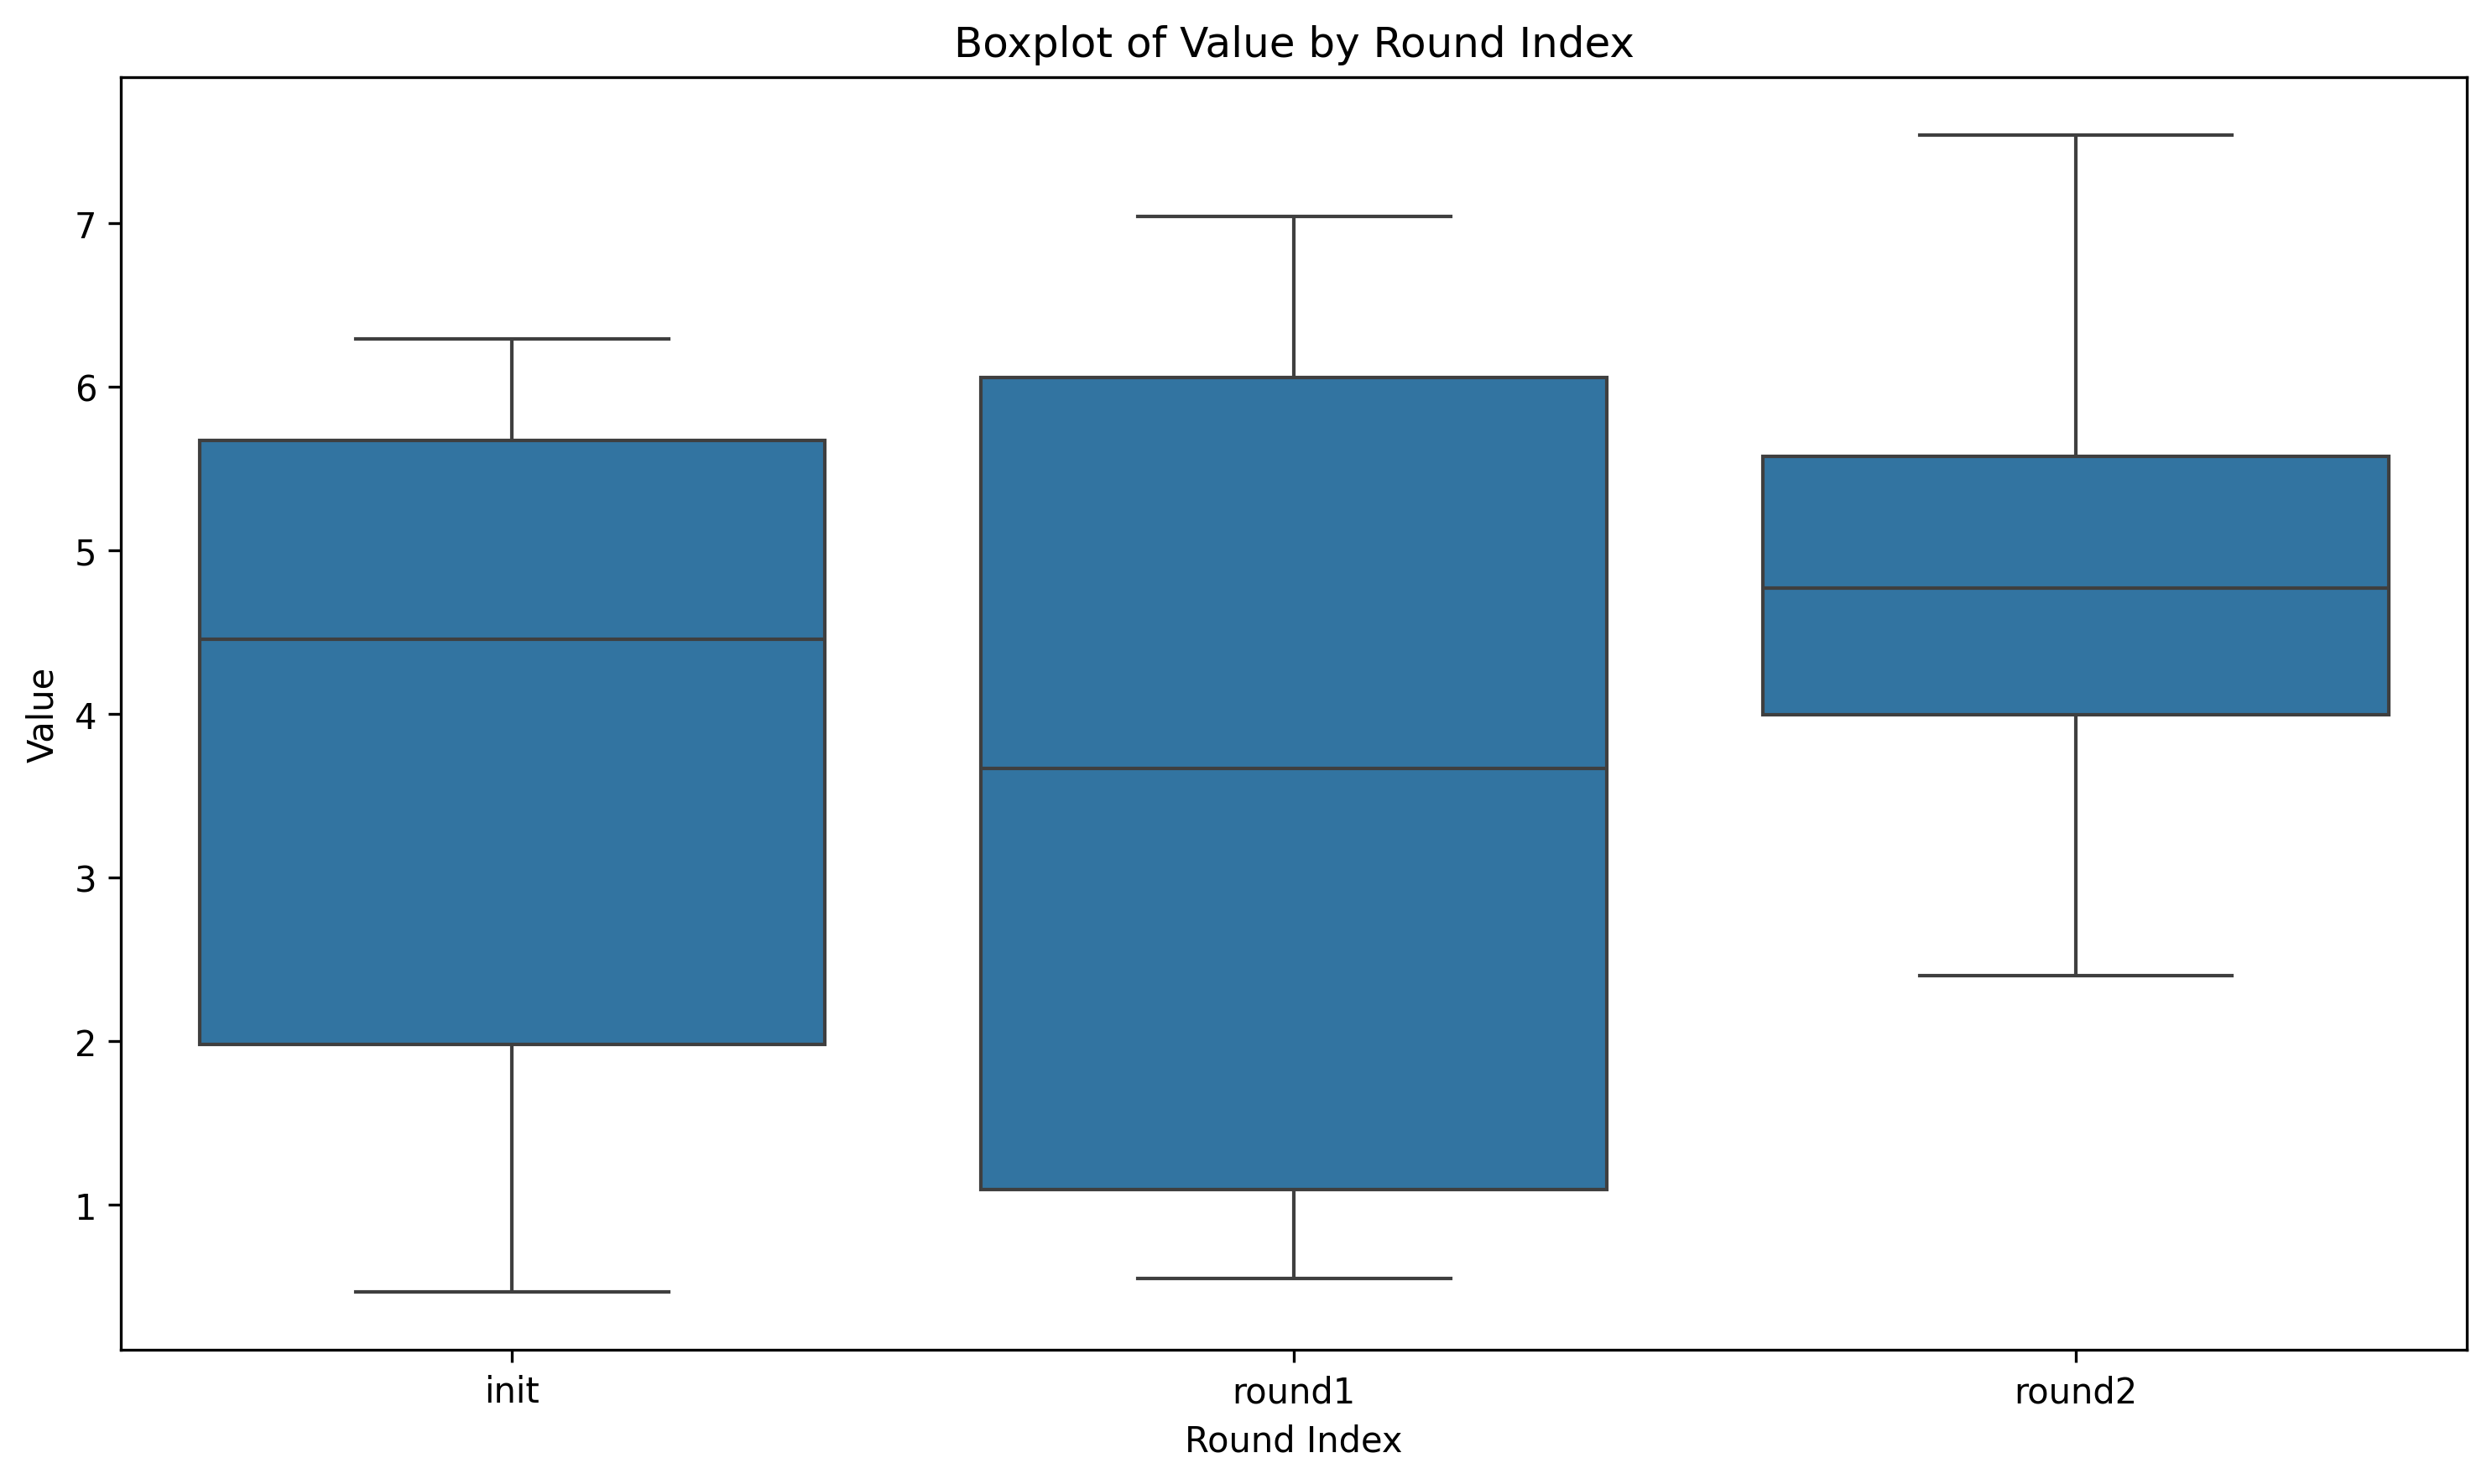

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
# Create boxplot
plt.figure(figsize=(10,6))
sns.boxplot(x='round', y='y', data=round_df)

# Add labels and title
plt.xlabel('Exp Round')
plt.ylabel('capped mRNA [µg/µL]')
#plt.title('Boxplot of Value by Round Index')

# Show the plot
plt.tight_layout()
plt.savefig('../figures/rounds_boxplot.png')